# NTf$_2^-$ dihedral distributions at 310 K

Structures (a), joint densities (b–e; SO3LR first), and separate distributions of $\varphi_1$ and $\varphi_2$ (f,g) over 0–360°.

The four heatmaps share a square-root colour scale. The one-angle distributions are calculated directly from the joint densities, with no folding or averaging of the two torsions. This notebook reads the existing compact CSV and writes the PNG figure.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import PowerNorm

cwd = Path.cwd().resolve()
chapter = next(
    path for path in (cwd, cwd.parent, cwd / '06_dihedrals')
    if (path / 'data' / 'dihedral_histograms_310K.csv').is_file()
)
OUT = chapter / 'figures'
OUT.mkdir(exist_ok=True)
SOURCE = chapter / 'data' / 'dihedral_histograms_310K.csv'
table=pd.read_csv(SOURCE)
order=['SO3LR','APPLE&P','CL&P','CL&P-scaled']
colors={'APPLE&P':'#0078b8','SO3LR':'#ed7d31','CL&P':'#009e73','CL&P-scaled':'#c83817'}
centres=np.arange(2.5,360,5);edges=np.arange(0,361,5)
dens={n:table[table.force_field==n].pivot(index='phi_1_deg',columns='phi_2_deg',values='probability_density_deg_minus2').loc[centres,centres].to_numpy() for n in order}
vmax=max(d.max() for d in dens.values())
plt.rcParams.update({'font.family':'DejaVu Sans','mathtext.fontset':'dejavusans',
 'font.size':18,'axes.labelsize':22,'axes.titlesize':20,'xtick.labelsize':18,'ytick.labelsize':18,
 'axes.linewidth':1.4,'xtick.major.width':1.4,'ytick.major.width':1.4,
 'xtick.major.size':5,'ytick.major.size':5,'svg.fonttype':'none','pdf.fonttype':42,'ps.fonttype':42})



In [2]:
def structure(ax,which):
    xy=np.array([[0,0],[1.25,.65],[2.5,0],[3.75,.65],[5,0.]])
    # Highlight the atoms defining each torsion and its central bond.
    color='#303030';muted='#929292';active=range(4) if which==1 else range(1,5)
    for k in range(4):
        p,q=xy[k:k+2];v=(q-p)/np.linalg.norm(q-p)
        ax.plot(*np.stack([p+.26*v,q-.26*v]).T,color=color if k in (range(3) if which==1 else range(1,4)) else muted,lw=3.6 if k==which else 2.1,solid_capstyle='round')
    for s in [1,3]:
        for dx in [-.45,.45]:
            end=xy[s]+[dx,.87];v=(end-xy[s])/np.linalg.norm(end-xy[s]);perp=np.array([-v[1],v[0]])*.032
            for sign in [-1,1]:ax.plot(*np.stack([xy[s]+.24*v+sign*perp,end-.17*v+sign*perp]).T,color=muted,lw=1.3)
            ax.text(*end,'O',ha='center',va='center',fontsize=19,color=muted)
    for k,label in enumerate([r'C$_1$',r'S$_1$',r'N$^{-}$',r'S$_2$',r'C$_2$']):
        ax.text(*xy[k],label,ha='center',va='center',fontsize=23,color=color if k in active else muted,bbox=dict(facecolor='white',edgecolor='none',pad=.5))
    for k in [0,4]:ax.text(xy[k,0],-.43,r'(CF$_3$)',ha='center',va='center',fontsize=17,color=muted)
    formula=r'$\varphi_1=\mathrm{dih}(\mathrm{C}_1,\mathrm{S}_1,\mathrm{N},\mathrm{S}_2)$' if which==1 else r'$\varphi_2=\mathrm{dih}(\mathrm{S}_1,\mathrm{N},\mathrm{S}_2,\mathrm{C}_2)$'
    ax.text(2.5,-1.0,formula,ha='center',va='center',fontsize=22,color=color)
    ax.set(xlim=(-.5,5.5),ylim=(-1.25,1.85),aspect='equal');ax.axis('off')




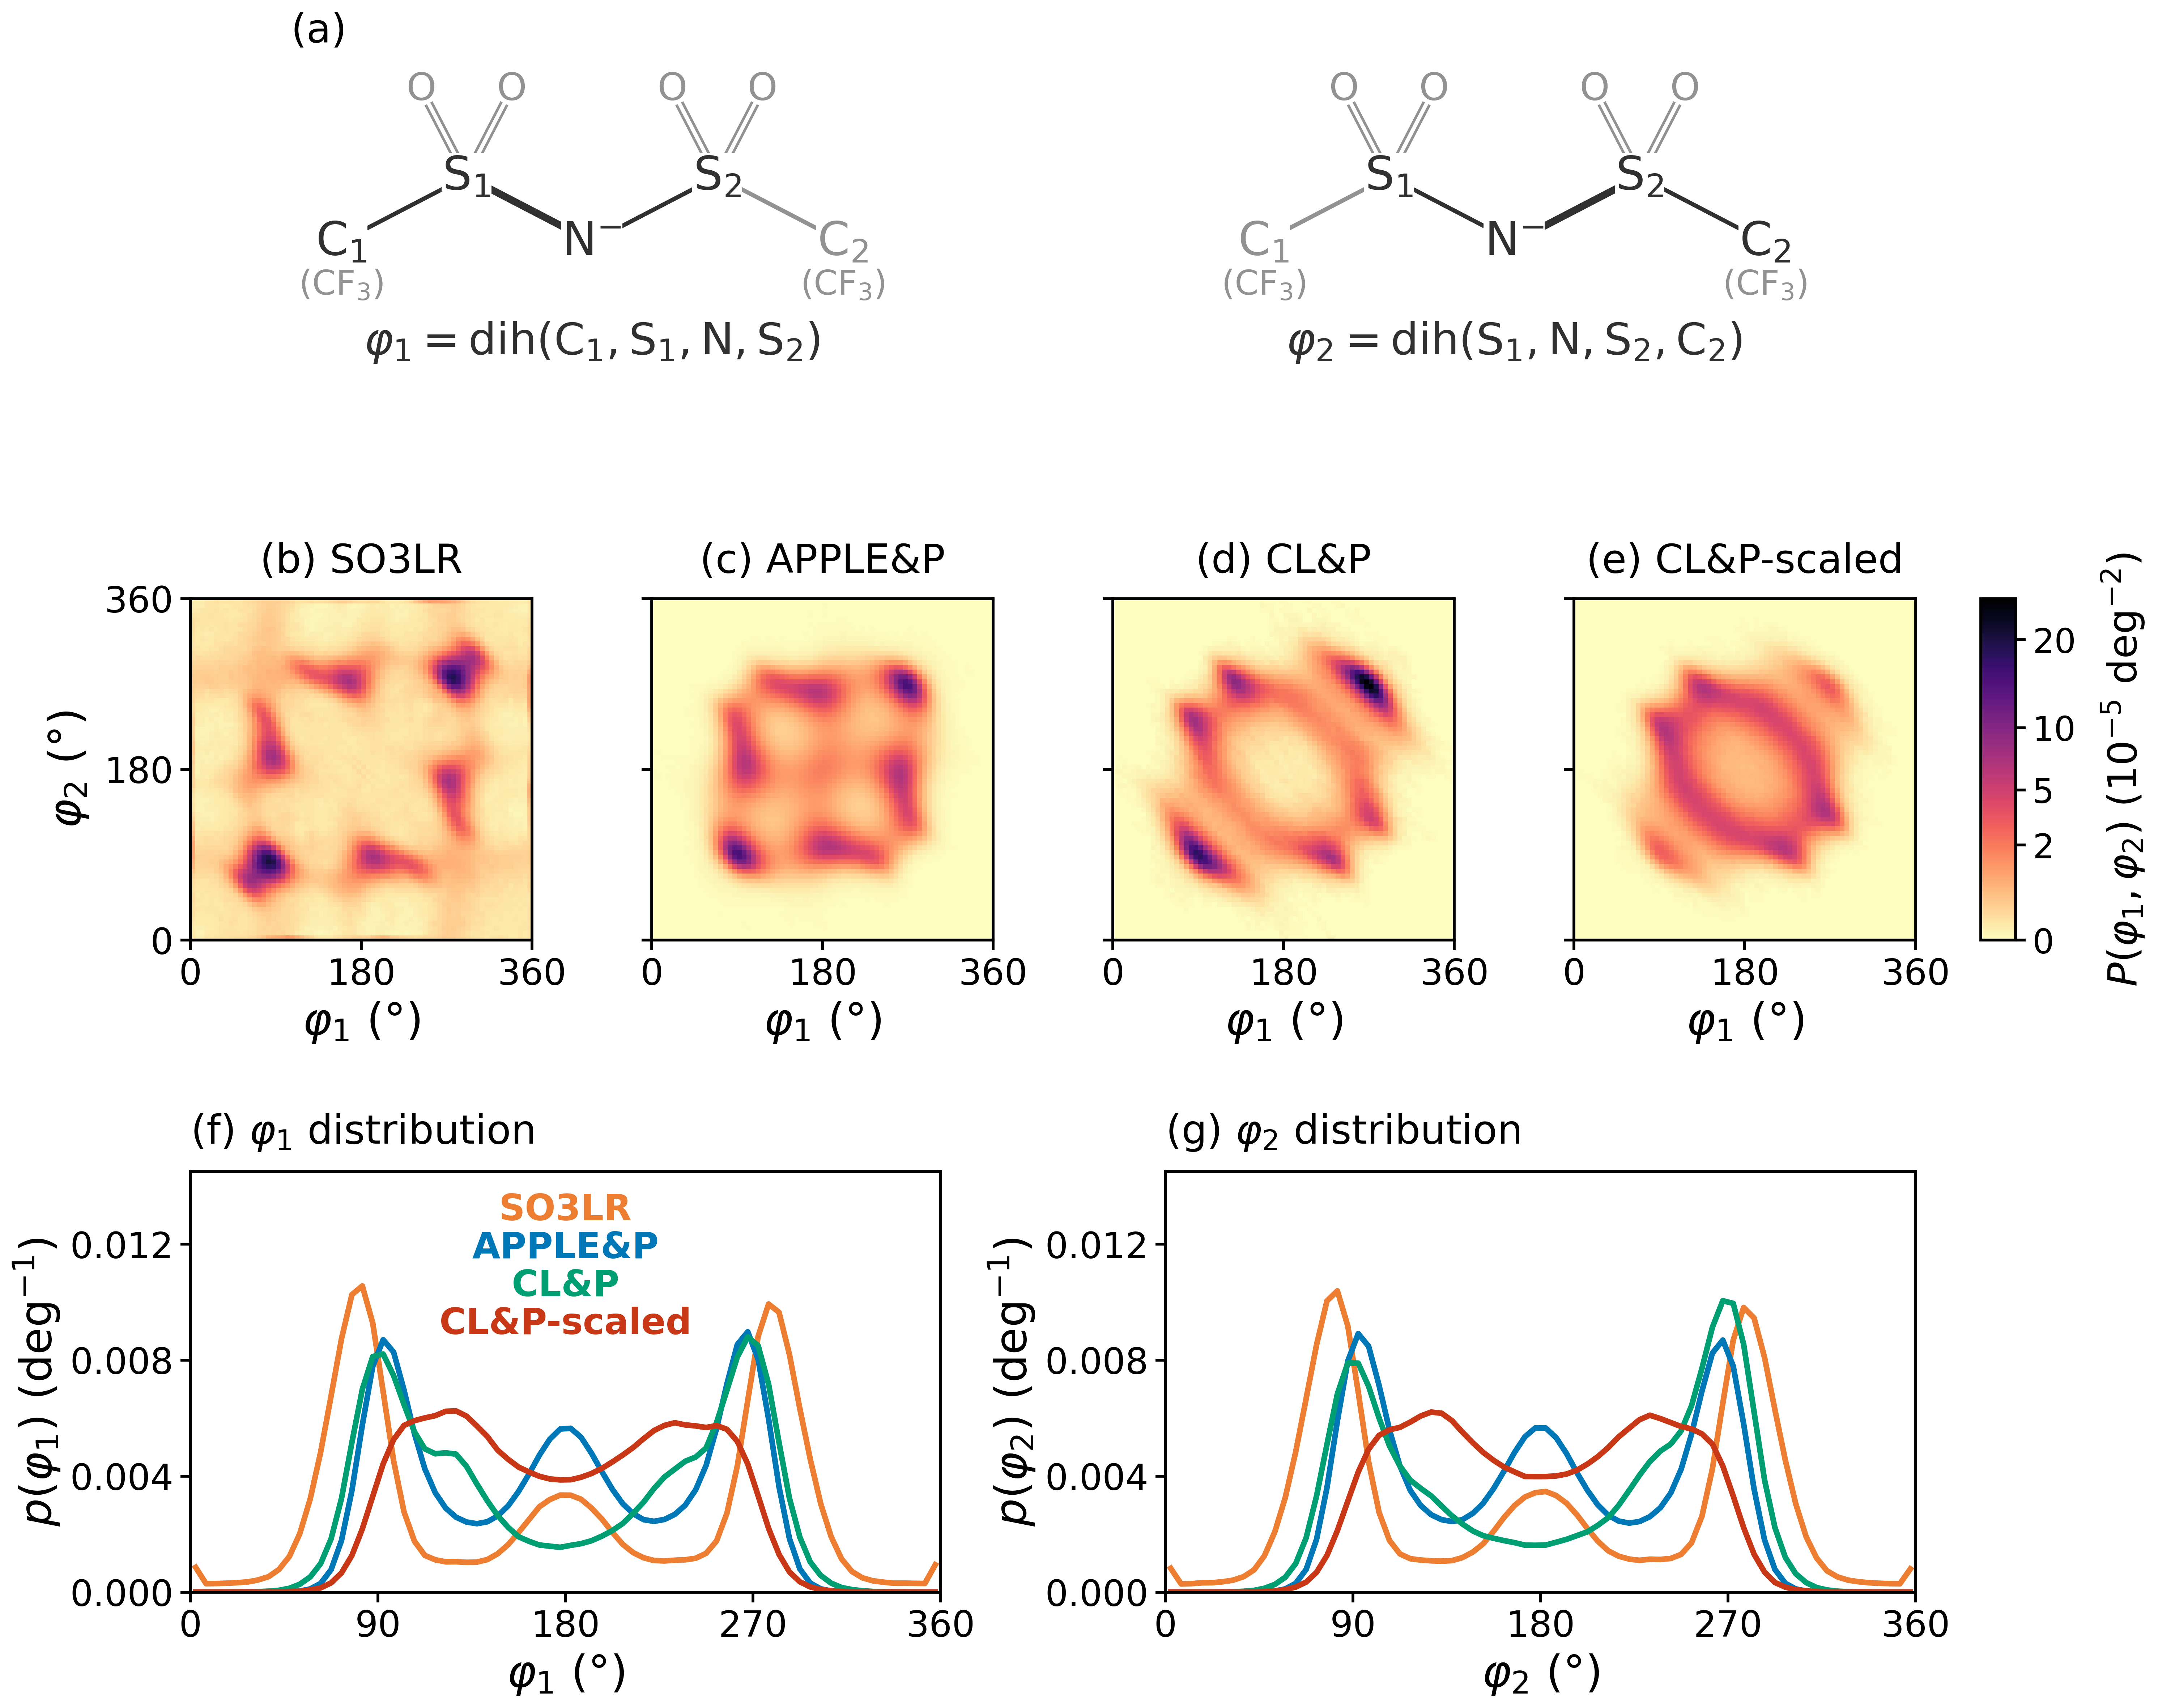

In [3]:
fig=plt.figure(figsize=(15,12))
gs=fig.add_gridspec(3,4,height_ratios=[.85,1,1.15],
 left=.08,right=.875,bottom=.085,top=.97,wspace=.35,hspace=.60)
structure_left=fig.add_subplot(gs[0,:2])
structure(structure_left,1);structure(fig.add_subplot(gs[0,2:]),2)
structure_left.text(0,1.02,'(a)',transform=structure_left.transAxes,
                    fontsize=20,ha='left',va='bottom')
scale=1e-5
norm=PowerNorm(gamma=.5,vmin=0,vmax=vmax/scale)
heat_axes=[]
for k,name in enumerate(order):
 ax=fig.add_subplot(gs[1,k]);heat_axes.append(ax)
 im=ax.pcolormesh(edges,edges,dens[name].T/scale,cmap='magma_r',norm=norm,rasterized=True)
 ax.set(xlim=(0,360),ylim=(0,360),xticks=[0,180,360],yticks=[0,180,360],
        aspect='equal',xlabel=r'$\varphi_1$ (°)')
 ax.set_title(f'({chr(98+k)}) {name}',pad=13)
 if k==0:ax.set_ylabel(r'$\varphi_2$ (°)',labelpad=7)
 else:ax.tick_params(labelleft=False)
fig.canvas.draw()
position=heat_axes[-1].get_position()
cax=fig.add_axes([.905,position.y0,.016,position.height])
cb=fig.colorbar(im,cax=cax,ticks=[0,2,5,10,20]);cb.ax.minorticks_off()
cb.set_label(r'$P(\varphi_1,\varphi_2)$ ($10^{-5}$ deg$^{-2}$)',fontsize=20,labelpad=12)
cb.ax.tick_params(labelsize=17)

bottom=gs[2,:].subgridspec(1,2,wspace=.30)
curve_axes=[fig.add_subplot(bottom[0,j]) for j in range(2)]
integrals={}
for name in order:
 integrals[name]={}
 for j,axis in enumerate([1,0]):
  marginal=dens[name].sum(axis=axis)*5
  integrals[name][f'phi{j+1}']=float(marginal.sum()*5)
  assert np.isclose(integrals[name][f'phi{j+1}'],1,atol=1e-12,rtol=0)
  curve_axes[j].plot(centres,marginal,color=colors[name],lw=2.8)
for j,ax in enumerate(curve_axes):
 ax.set(xlim=(0,360),ylim=(0,.0145),xticks=[0,90,180,270,360],yticks=[0,.004,.008,.012],
        xlabel=rf'$\varphi_{j+1}$ (°)',ylabel=rf'$p(\varphi_{j+1})$ (deg$^{{-1}}$)')
 ax.set_title(f'({chr(102+j)}) '+rf'$\varphi_{j+1}$ distribution',loc='left',pad=14)
for i,name in enumerate(order):
 curve_axes[0].text(.50,.95-.09*i,name,transform=curve_axes[0].transAxes,
                    color=colors[name],fontsize=18,fontweight='bold',ha='center',va='top')
fig.savefig(OUT / 'dihedral_comparison_310K.png', dpi=400, facecolor='white',
            bbox_inches='tight', pad_inches=.08)
plt.close(fig)

from IPython.display import Image, display
display(Image(filename=str(OUT / 'dihedral_comparison_310K.png'), width=1100))
